In [1]:
import pandas as pd

url = (
    "https://raw.githubusercontent.com/swejal22/"
    "parent-child-independence-project/main/"
    "pew_young_adults_clean_numeric.csv"
)

df = pd.read_csv(url)

print("Dataset shape:", df.shape)

print("\nFinancial independence categories:")
print(df["financial_independence"].value_counts(dropna=False))

print("\nMissing values:")
print(df[
    [
        "financial_independence",
        "received_financial_help",
        "lives_with_parents",
        "parent_involvement_level",
        "communication_satisfaction",
        "employment_status",
        "age_group"
    ]
].isna().sum())

Dataset shape: (1495, 30)

Financial independence categories:
financial_independence
1.0    792
2.0    341
3.0    165
4.0    119
5.0     74
NaN      4
Name: count, dtype: int64

Missing values:
financial_independence        4
received_financial_help       0
lives_with_parents            2
parent_involvement_level      7
communication_satisfaction    7
employment_status             3
age_group                     0
dtype: int64


In [2]:
# labeled data for Naive Bayes

target = "financial_independence"

features = [
    "received_financial_help",
    "lives_with_parents",
    "parent_involvement_level",
    "communication_satisfaction",
    "employment_status",
    "age_group"
]

model_df = df[features + [target]].dropna().copy()


X = model_df[features]
y = model_df[target].astype(int)

print("Cleaned dataset shape:", model_df.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nFeature minimum values:")
print(X.min())

print("\nFirst five rows:")
display(model_df.head())

Cleaned dataset shape: (1478, 7)

Target distribution:
financial_independence
1    786
2    338
3    163
4    117
5     74
Name: count, dtype: int64

Feature minimum values:
received_financial_help       1.0
lives_with_parents            1.0
parent_involvement_level      1.0
communication_satisfaction    1.0
employment_status             1.0
age_group                     1.0
dtype: float64

First five rows:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group,financial_independence
0,1.0,1.0,1.0,3.0,2.0,1,2.0
1,2.0,3.0,3.0,3.0,1.0,1,1.0
2,2.0,3.0,3.0,3.0,2.0,2,1.0
3,2.0,3.0,3.0,2.0,1.0,1,4.0
4,1.0,3.0,3.0,1.0,1.0,2,2.0


In [3]:


for column in features + [target]:
    print(f"\n{column}")
    print(model_df[column].value_counts().sort_index())



received_financial_help
received_financial_help
1.0    571
2.0    907
Name: count, dtype: int64

lives_with_parents
lives_with_parents
1.0     216
2.0     147
3.0    1115
Name: count, dtype: int64

parent_involvement_level
parent_involvement_level
1.0     121
2.0     316
3.0    1041
Name: count, dtype: int64

communication_satisfaction
communication_satisfaction
1.0     83
2.0    403
3.0    992
Name: count, dtype: int64

employment_status
employment_status
1.0    1023
2.0     212
3.0     216
4.0      25
5.0       2
Name: count, dtype: int64

age_group
age_group
1    736
2    742
Name: count, dtype: int64

financial_independence
financial_independence
1.0    786
2.0    338
3.0    163
4.0    117
5.0     74
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Split original labeled observations first
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# One-hot encode categorical survey responses
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

feature_names = encoder.get_feature_names_out(features)

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=feature_names,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=feature_names,
    index=X_test.index
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

print("\nOverlapping row indices:",
      len(set(X_train.index) & set(X_test.index)))

print("\nEncoded training sample:")
display(X_train_encoded.head())

Training observations: 1182
Testing observations: 296

Training shape: (1182, 18)
Testing shape: (296, 18)

Overlapping row indices: 0

Encoded training sample:


,received_financial_help_1.0,received_financial_help_2.0,lives_with_parents_1.0,lives_with_parents_2.0,lives_with_parents_3.0,parent_involvement_level_1.0,parent_involvement_level_2.0,parent_involvement_level_3.0,communication_satisfaction_1.0,communication_satisfaction_2.0,communication_satisfaction_3.0,employment_status_1.0,employment_status_2.0,employment_status_3.0,employment_status_4.0,employment_status_5.0,age_group_1,age_group_2
714,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
237,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
37,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
689,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1302,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


Labeled data sample:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group,financial_independence
0,1.0,1.0,1.0,3.0,2.0,1,2.0
1,2.0,3.0,3.0,3.0,1.0,1,1.0
2,2.0,3.0,3.0,3.0,2.0,2,1.0
3,2.0,3.0,3.0,2.0,1.0,1,4.0
4,1.0,3.0,3.0,1.0,1.0,2,2.0


Training data sample:


,received_financial_help_1.0,received_financial_help_2.0,lives_with_parents_1.0,lives_with_parents_2.0,lives_with_parents_3.0,parent_involvement_level_1.0,parent_involvement_level_2.0
714,1.0,0.0,1.0,0.0,0.0,0.0,0.0
237,0.0,1.0,0.0,0.0,1.0,0.0,0.0
37,0.0,1.0,0.0,0.0,1.0,0.0,0.0
689,1.0,0.0,0.0,0.0,1.0,0.0,1.0
1302,0.0,1.0,0.0,1.0,0.0,0.0,0.0


Testing data sample:


,received_financial_help_1.0,received_financial_help_2.0,lives_with_parents_1.0,lives_with_parents_2.0,lives_with_parents_3.0,parent_involvement_level_1.0,parent_involvement_level_2.0
1044,0.0,1.0,0.0,0.0,1.0,0.0,0.0
111,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1267,1.0,0.0,0.0,1.0,0.0,0.0,1.0
856,1.0,0.0,0.0,0.0,1.0,0.0,0.0
675,0.0,1.0,0.0,0.0,1.0,0.0,0.0


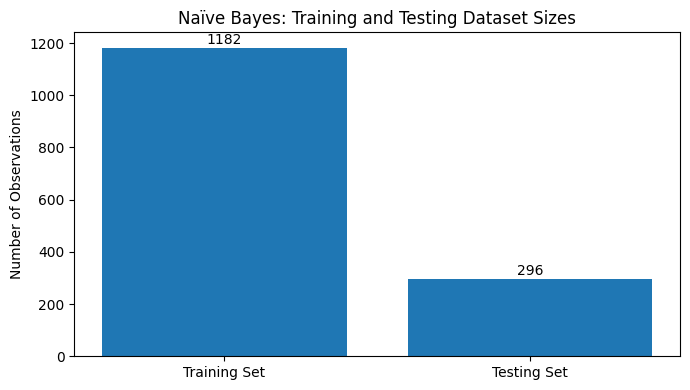

In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

# Save the cleaned labeled dataset
model_df.to_csv("nb_labeled_data.csv", index=False)

# Save training and testing datasets with labels
train_export = X_train_encoded.copy()
train_export["financial_independence"] = y_train

test_export = X_test_encoded.copy()
test_export["financial_independence"] = y_test

train_export.to_csv("nb_training_data.csv", index=False)
test_export.to_csv("nb_testing_data.csv", index=False)

# Show samples
print("Labeled data sample:")
display(model_df.head())

print("Training data sample:")
display(train_export.iloc[:5, :7])

print("Testing data sample:")
display(test_export.iloc[:5, :7])

# Visualize train/test split
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ["Training Set", "Testing Set"],
    [len(X_train), len(X_test)]
)

ax.set_title("Naïve Bayes: Training and Testing Dataset Sizes")
ax.set_ylabel("Number of Observations")

for i, value in enumerate([len(X_train), len(X_test)]):
    ax.text(i, value + 15, str(value), ha="center")

plt.tight_layout()
plt.savefig("nb_train_test_split.png", dpi=200)
plt.show()

In [6]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

nb_model = MultinomialNB(alpha=1.0)

nb_model.fit(X_train_encoded, y_train)

# Predict financial independence categories
y_pred_nb = nb_model.predict(X_test_encoded)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Multinomial Naive Bayes Accuracy:")
print(f"{nb_accuracy:.4f} ({nb_accuracy * 100:.2f}%)")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb, labels=[1, 2, 3, 4, 5]))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_nb,
        labels=[1, 2, 3, 4, 5],
        zero_division=0
    )
)

Multinomial Naive Bayes Accuracy:
0.5912 (59.12%)

Confusion Matrix:
[[128  23   5   0   1]
 [ 24  35   7   1   1]
 [ 13  11   3   4   2]
 [  0   9   3   5   6]
 [  1   5   1   4   4]]

Classification Report:
              precision    recall  f1-score   support

           1       0.77      0.82      0.79       157
           2       0.42      0.51      0.46        68
           3       0.16      0.09      0.12        33
           4       0.36      0.22      0.27        23
           5       0.29      0.27      0.28        15

    accuracy                           0.59       296
   macro avg       0.40      0.38      0.38       296
weighted avg       0.57      0.59      0.57       296



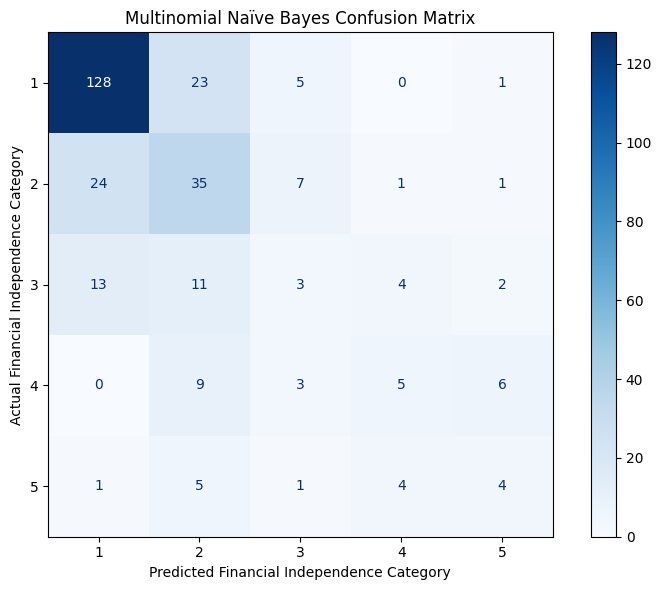

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    labels=[1, 2, 3, 4, 5],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Multinomial Naïve Bayes Confusion Matrix")
ax.set_xlabel("Predicted Financial Independence Category")
ax.set_ylabel("Actual Financial Independence Category")

plt.tight_layout()
plt.savefig("nb_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

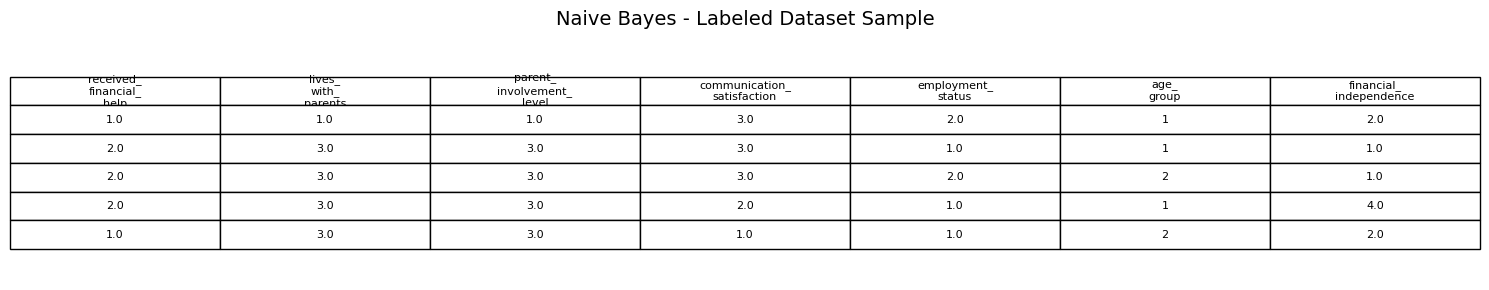

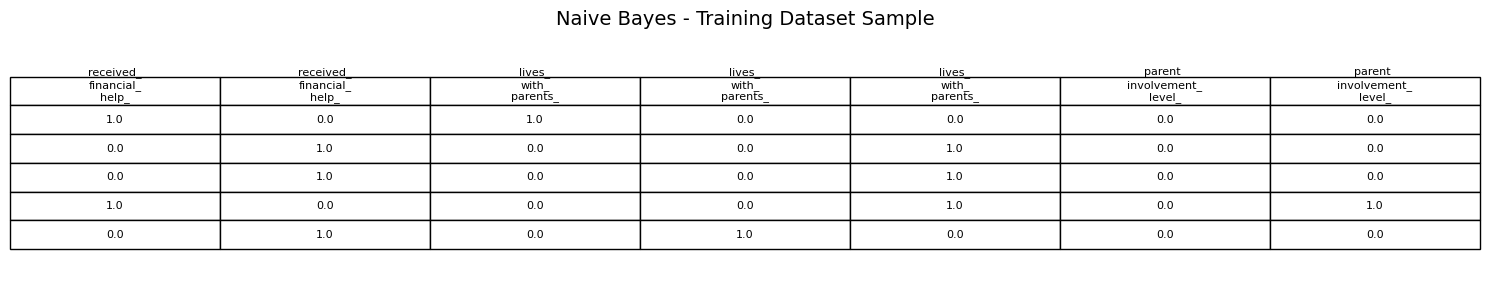

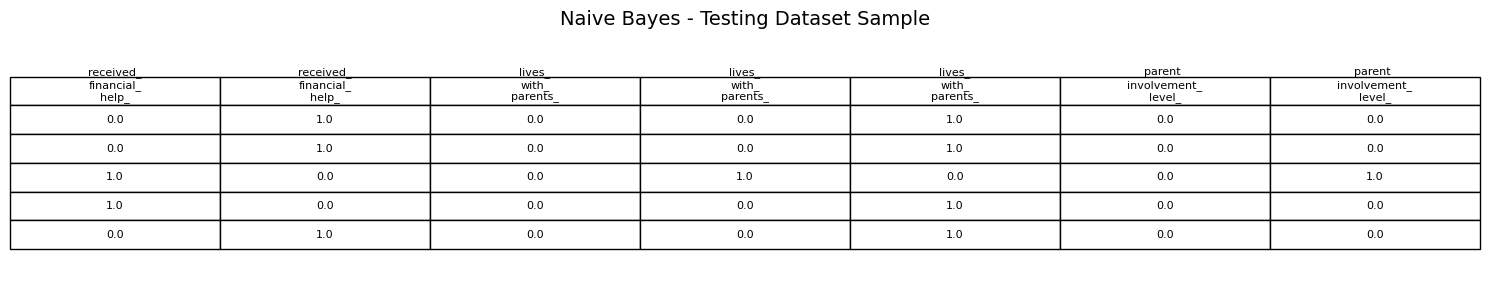

In [8]:
import matplotlib.pyplot as plt

def save_sample_image(data, title, filename):
    sample = data.head(5).iloc[:, :7].copy()

    fig, ax = plt.subplots(figsize=(15, 3))
    ax.axis("off")

    # Make long column names easier to read
    sample.columns = [
        str(col).replace("_", "_\n")
        for col in sample.columns
    ]

    table = ax.table(
        cellText=sample.astype(str).values,
        colLabels=sample.columns,
        loc="center",
        cellLoc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.7)

    ax.set_title(title, fontsize=14, pad=15)

    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

# Image 1: Labeled dataset
save_sample_image(
    model_df,
    "Naive Bayes - Labeled Dataset Sample",
    "nb_labeled_sample.png"
)

# Image 2: Training dataset
save_sample_image(
    train_export,
    "Naive Bayes - Training Dataset Sample",
    "nb_training_sample.png"
)

# Image 3: Testing dataset
save_sample_image(
    test_export,
    "Naive Bayes - Testing Dataset Sample",
    "nb_testing_sample.png"
)